# Análise dos Dados STN-PLAD
***

* Repositório com o dataset original: [STN PLAD Dataset](https://github.com/andreluizbvs/PLAD).
* Publicação do artigo científico: [STN PLAD: A Dataset for Multi-Size Power Line Assets Detection in High-Resolution UAV Images](https://arxiv.org/pdf/2108.07944v3.pdf).

### Importação dos Pacotes Utilitários
***

In [1]:
from collections import Counter
import matplotlib.pyplot as plt
import json, os
import utils

### Análise dos Dados
***

Tipos de classes de objetos distintos explorados no conjunto de imagens proposto:

* ```tower```: Uma torre de transmissão é uma estrutura metálica em forma de torre que sustenta uma série de cabos através dos quais é transportada a energia elétrica. 
* ```insulator```: Os isoladores são os componentes das linhas de transmissão responsáveis pelo isolamento e sustentação mecânica dos cabos condutores.
* ```spacer```: Os espaçadores são os principais componentes do sistema de amortecimento da linha de transmissão, evitando que os cabos condutores de energia se choquem com a movimentação do vento.
* ```damper```: Um amortecedor Stockbridge é um amortecedor de massa sintonizado usado para suprimir as vibrações induzidas pelo vento em estruturas esbeltas, como linhas de energia aéreas, sinais longos em balanço e pontes estaiadas.
* ```plate```: As placas são usadas para a indicação de fios de alta tensão, cercas, portões e paredes em locais necessários.

In [2]:
# carregando os rótulos no arquivo json dentro de um dicionário
json_path = '../datasets-descompactados/STN-PLAD-dataset/annotations.json'
data = utils.load_json_file(json_path)

In [3]:
# analisando as chaves de acesso do dicionário
data.keys()

dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])

In [4]:
# analisando as informações do conjunto de imagens
data['info']

{'description': 'Dataset for powerline inspection.',
 'url': 'https://github.com/andreluizbvs/PLAD',
 'version': '1.0',
 'year': 2021,
 'contributor': 'STN - In Forma - Voxar Labs',
 'date_created': '2020/03/03'}

In [5]:
# analisando as categorias de rotulação dos dados com seus respectivos IDs
data['categories']

[{'supercategory': 'tower', 'id': 0, 'name': 'tower'},
 {'supercategory': 'component', 'id': 1, 'name': 'insulator'},
 {'supercategory': 'component', 'id': 2, 'name': 'spacer'},
 {'supercategory': 'component', 'id': 3, 'name': 'damper'},
 {'supercategory': 'component', 'id': 5, 'name': 'plate'}]

In [6]:
# inicializando um dicionário vazio com os IDs das imagens
images_ids = utils.initialize_images_ids_with_dict(data)

# obtendo a quantidade de instâncias de objeto por imagem
for info in data['annotations']:
    images_ids[info['image_id']].append(info['category_id'])

In [7]:
# verificando se todas as imagens estão contemplada com os respectivos rótulos
directory1 = len(os.listdir('../datasets-descompactados/STN-PLAD-dataset/20181127-A1'))
directory2 = len(os.listdir('../datasets-descompactados/STN-PLAD-dataset/20181129-R'))
len(images_ids) == directory1 + directory2

True

In [8]:
# contando a quantidade de instâncias de objetos em todo o conjunto de imagens
count_instances = {'Torres': 0, 'Isoladores': 0, 'Espaçadores': 0, 'Amortecedores': 0, 'Sinalização': 0}

for images_instances in images_ids.values():
    count_aux = Counter(images_instances)
    count_instances['Torres'] += count_aux[0]
    count_instances['Isoladores'] += count_aux[1]
    count_instances['Espaçadores'] += count_aux[2]
    count_instances['Amortecedores'] += count_aux[3]
    count_instances['Sinalização'] += count_aux[5]

print(count_instances)

{'Torres': 253, 'Isoladores': 312, 'Espaçadores': 253, 'Amortecedores': 1505, 'Sinalização': 86}


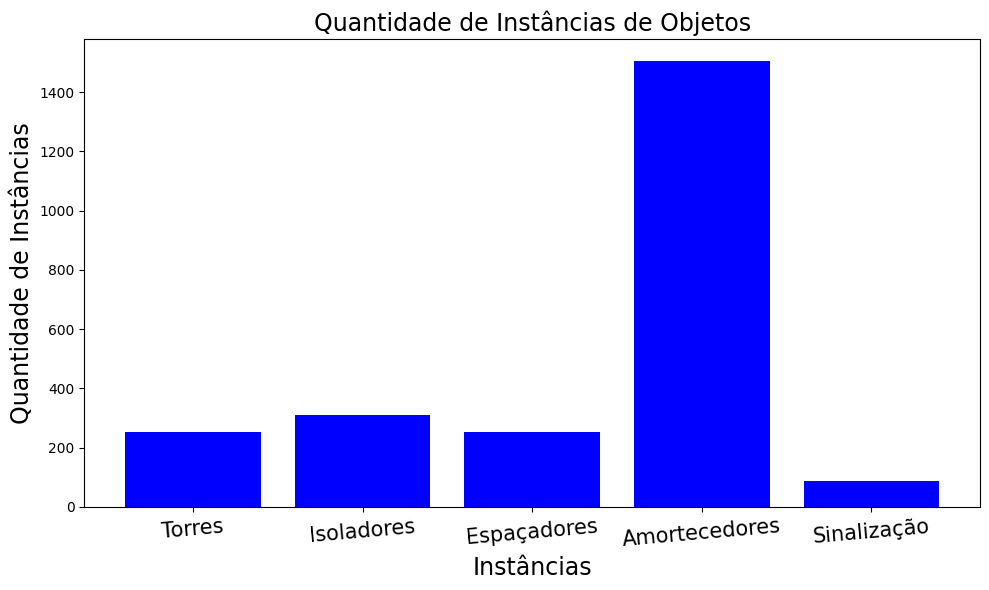

In [9]:
# extraindo as chaves e os valores do dicionário
classes = list(count_instances.keys())
quantities = list(count_instances.values())

# configurações para a plotagem do gráfico de barras
plt.figure(figsize = (10, 6))  

plt.bar(classes, quantities, color = 'blue')  

plt.xlabel('Instâncias', size = 17)
plt.ylabel('Quantidade de Instâncias', size = 17)
plt.title('Quantidade de Instâncias de Objetos', size = 17)
plt.xticks(rotation = 5, size = 15)  

plt.tight_layout()
plt.show()

In [10]:
# contando a quantidade de instâncias de objetos em todo o conjunto de imagens
verify_towers = {'Imagens com Torres': 0, 'Imagens sem Torres': 0}

for images_instances in images_ids.values():
    count_aux = Counter(images_instances)
    if count_aux[0] != 0:
        verify_towers['Imagens com Torres'] += 1
    else:
        verify_towers['Imagens sem Torres'] += 1

print(verify_towers)

{'Imagens com Torres': 131, 'Imagens sem Torres': 2}


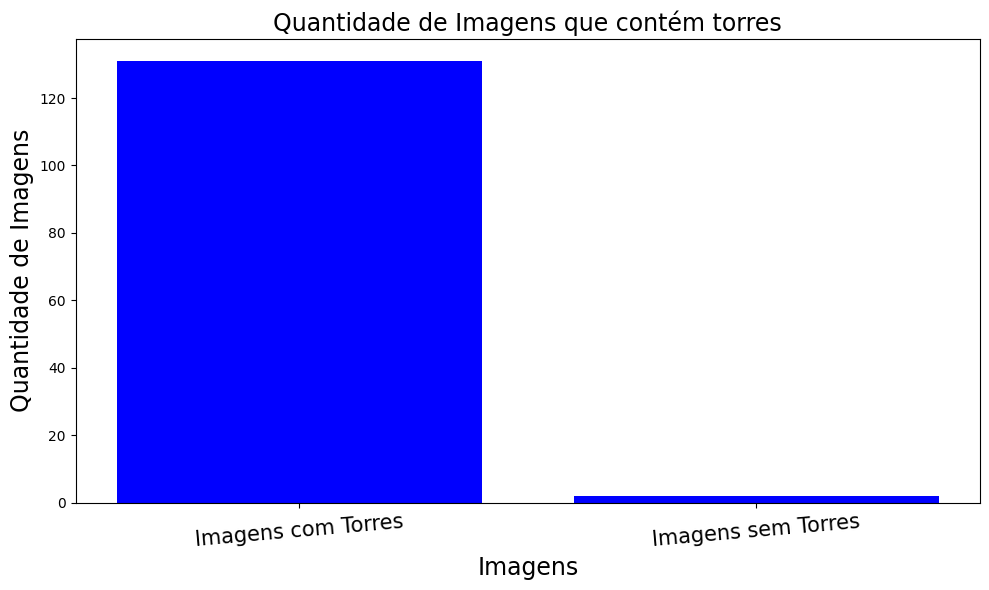

In [11]:
# extraindo as chaves e os valores do dicionário
classes = list(verify_towers.keys())
quantities = list(verify_towers.values())

# configurações para a plotagem do gráfico de barras
plt.figure(figsize = (10, 6))  

plt.bar(classes, quantities, color='blue')  

plt.xlabel('Imagens', size = 17)
plt.ylabel('Quantidade de Imagens', size = 17)
plt.title('Quantidade de Imagens que contém torres', size = 17)
plt.xticks(rotation = 5, size = 15)  

plt.tight_layout()  
plt.show()  